In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/MVJ_Internship/Data")

file_1 = data_dir / "online_retail_II_csv(2009-2010).csv"
file_2 = data_dir / "online_retail_II_csv(2010-2011).csv"

print("First file exists:", file_1.exists())
print("Second file exists:", file_2.exists())

First file exists: True
Second file exists: True


In [ ]:
#check the contents of both the files
df_1 = pd.read_csv(
    file_1,
    low_memory=False,
    dtype={"Invoice": "string", "StockCode": "string"},
    encoding="latin1"
)

df_2 = pd.read_csv(
    file_2,
    low_memory=False,
    dtype={"Invoice": "string", "StockCode": "string"},
    encoding="latin1"
)

raw_df = pd.concat([df_1, df_2], ignore_index=True)

print("2009-10 rows and columns:", df_1.shape)
print("2010-2011 rows and columns:", df_2.shape)
print("Combined rows and columns:", raw_df.shape)

display(raw_df.head())

2009-10 rows and columns: (525461, 8)
2010-2011 rows and columns: (541910, 8)
Combined rows and columns: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,01-12-09,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,01-12-09,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,01-12-09,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,01-12-09,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,01-12-09,1.25,13085.0,United Kingdom


In [ ]:
#load and combine the data
df_1 = pd.read_csv(
    file_1, low_memory=False,
    dtype={"Invoice": "string", "StockCode": "string"},
    encoding="latin1"
)

df_2 = pd.read_csv(
    file_2, low_memory=False,
    dtype={"Invoice": "string", "StockCode": "string"},
    encoding="latin1"
)

df = pd.concat([df_1, df_2], ignore_index=True)

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1067371, 8)


/tmp/ipykernel_555/3236949288.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["InvoiceDate"] = pd.to_datetime(


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-01-12,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-01-12,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-01-12,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-01-12,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-01-12,1.25,13085.0,United Kingdom


In [ ]:
#prepare the revenue data
sales = df.copy()

sales["Invoice"] = sales["Invoice"].astype("string").str.strip()

sales = sales[
    sales["InvoiceDate"].notna()
    & sales["Quantity"].gt(0)
    & sales["Price"].gt(0)
    & ~sales["Invoice"].str.upper().str.startswith("C", na=False)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["Price"]

print("Rows in original data:", len(df))
print("Rows used for sales analysis:", len(sales))
print("Total revenue:", round(sales["Revenue"].sum(), 2))

Rows in original data: 1067371
Rows used for sales analysis: 1041670
Total revenue: 20972594.57


In [ ]:
#use GROUPBY() to calculate daily revenue
daily_revenue = (
    sales.groupby(sales["InvoiceDate"].dt.date)
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoice_Count=("Invoice", "nunique")
    )
    .reset_index()
    .rename(columns={"InvoiceDate": "Date"})
)

daily_revenue["Date"] = pd.to_datetime(daily_revenue["Date"])
daily_revenue = daily_revenue.sort_values("Date")

display(daily_revenue.head(10))
print("Number of daily records:", len(daily_revenue))

,Date,Revenue,Units_Sold,Invoice_Count
0,2009-01-12,54513.50,26204,119
1,2009-02-12,63352.51,31896,115
2,2009-03-12,74037.91,49243,124
3,2009-04-12,40732.92,21325,89
4,2009-05-12,9803.05,5119,30
5,2009-06-12,24613.64,11623,74
6,2009-07-12,45083.35,18058,101
7,2009-08-12,49517.23,23159,109
8,2009-09-12,40616.09,17934,88
9,2009-10-12,44442.11,23718,92


Number of daily records: 604


In [ ]:
#use GROUPBY() to calculate monthly revenue
sales["Month"] = sales["InvoiceDate"].dt.to_period("M").astype(str)

monthly_revenue = (
    sales.groupby("Month")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoice_Count=("Invoice", "nunique")
    )
    .reset_index()
)

display(monthly_revenue)

,Month,Revenue,Units_Sold,Invoice_Count
0,2009-01,54513.500,26204,119
1,2009-02,63352.510,31896,115
2,2009-03,74037.910,49243,124
3,2009-04,40732.920,21325,89
4,2009-05,9803.050,5119,30
5,2009-06,24613.640,11623,74
6,2009-07,45083.350,18058,101
7,2009-08,49517.230,23159,109
8,2009-09,40616.090,17934,88
9,2009-10,44442.110,23718,92


In [ ]:
#check with the date and revenue columns
# Check that the required columns exist
print("Sales shape:", sales.shape)
print("\nColumn data types:")
print(sales[["InvoiceDate", "Revenue"]].dtypes)

# Ensure InvoiceDate is datetime and Revenue is numeric
sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"], errors="coerce"
)
sales["Revenue"] = pd.to_numeric(
    sales["Revenue"], errors="coerce"
)

# Remove rows that cannot be used for time-series analysis
sales = sales.dropna(subset=["InvoiceDate", "Revenue"]).copy()

# Sort dates from oldest to newest
sales = sales.sort_values("InvoiceDate").reset_index(drop=True)

print("\nRows available for resampling:", len(sales))
print("Earliest date:", sales["InvoiceDate"].min())
print("Latest date:", sales["InvoiceDate"].max())

display(sales[["InvoiceDate", "Revenue"]].head())

Sales shape: (1041670, 10)

Column data types:
InvoiceDate    datetime64[ns]
Revenue               float64
dtype: object

Rows available for resampling: 1041670
Earliest date: 2009-01-12 00:00:00
Latest date: 2011-12-10 00:00:00


,InvoiceDate,Revenue
0,2009-01-12,83.40
1,2009-01-12,8.60
2,2009-01-12,12.90
3,2009-01-12,3.43
4,2009-01-12,8.60


In [ ]:
#daily revenue using resample()
# Create daily revenue, including dates with no sales
daily_series = (
    sales.set_index("InvoiceDate")
    .resample("D")["Revenue"]
    .sum()
    .rename("Revenue")
    .reset_index()
)

print("Daily resampling shape:", daily_series.shape)
display(daily_series.head(15))

# Alternative plain-text display if the table looks broken
print(daily_series.head(15).to_string(index=False))

Daily resampling shape: (1063, 2)


,InvoiceDate,Revenue
0,2009-01-12,54513.5
1,2009-01-13,0.0
2,2009-01-14,0.0
3,2009-01-15,0.0
4,2009-01-16,0.0
5,2009-01-17,0.0
6,2009-01-18,0.0
7,2009-01-19,0.0
8,2009-01-20,0.0
9,2009-01-21,0.0


InvoiceDate  Revenue
 2009-01-12  54513.5
 2009-01-13      0.0
 2009-01-14      0.0
 2009-01-15      0.0
 2009-01-16      0.0
 2009-01-17      0.0
 2009-01-18      0.0
 2009-01-19      0.0
 2009-01-20      0.0
 2009-01-21      0.0
 2009-01-22      0.0
 2009-01-23      0.0
 2009-01-24      0.0
 2009-01-25      0.0
 2009-01-26      0.0


In [ ]:
#debugging the empty dataframe problem
print("Number of rows in sales:", len(sales))
print("Columns:", sales.columns.tolist())

print("\nData types:")
print(sales[["InvoiceDate", "Revenue"]].dtypes)

print("\nMissing values:")
print(sales[["InvoiceDate", "Revenue"]].isna().sum())

print("\nFirst 5 rows:")
print(sales[["InvoiceDate", "Revenue"]].head().to_string(index=False))

Number of rows in sales: 1041670
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue', 'Month']

Data types:
InvoiceDate    datetime64[ns]
Revenue               float64
dtype: object

Missing values:
InvoiceDate    0
Revenue        0
dtype: int64

First 5 rows:
InvoiceDate  Revenue
 2009-01-12    83.40
 2009-01-12     8.60
 2009-01-12    12.90
 2009-01-12     3.43
 2009-01-12     8.60


In [ ]:
#since no. of rows in sales shows 0:
# Start again from the original combined dataset
sales = df.copy()

# Clean column names in case there are extra spaces
sales.columns = sales.columns.str.strip()

# Convert columns carefully
sales["Invoice"] = sales["Invoice"].astype("string").str.strip()

sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"],
    errors="coerce",
    dayfirst=True
)

sales["Quantity"] = pd.to_numeric(
    sales["Quantity"], errors="coerce"
)

sales["Price"] = pd.to_numeric(
    sales["Price"], errors="coerce"
)

# Check the data BEFORE filtering
print("Rows in original df:", len(df))
print("Valid dates:", sales["InvoiceDate"].notna().sum())
print("Valid quantities:", sales["Quantity"].notna().sum())
print("Valid prices:", sales["Price"].notna().sum())

display(sales[["Invoice", "InvoiceDate", "Quantity", "Price"]].head())

Rows in original df: 1067371
Valid dates: 1067371
Valid quantities: 1067371
Valid prices: 1067371


,Invoice,InvoiceDate,Quantity,Price
0,489434,2009-01-12,12,6.95
1,489434,2009-01-12,12,6.75
2,489434,2009-01-12,12,6.75
3,489434,2009-01-12,48,2.10
4,489434,2009-01-12,24,1.25


In [ ]:
# Apply the same sales-analysis filters
sales = sales[
    sales["InvoiceDate"].notna()
    & sales["Quantity"].gt(0)
    & sales["Price"].gt(0)
    & ~sales["Invoice"].str.upper().str.startswith("C", na=False)
].copy()

sales["Revenue"] = sales["Quantity"] * sales["Price"]
sales = sales.sort_values("InvoiceDate")

print("Rows after filtering:", len(sales))
print("Date range:", sales["InvoiceDate"].min(), "to", sales["InvoiceDate"].max())

display(sales[["InvoiceDate", "Revenue"]].head())

Rows after filtering: 1041670
Date range: 2009-01-12 00:00:00 to 2011-12-10 00:00:00


,InvoiceDate,Revenue
0,2009-01-12,83.40
2152,2009-01-12,8.60
2153,2009-01-12,12.90
2154,2009-01-12,3.43
2155,2009-01-12,8.60


In [ ]:
#try resampling again
daily_series = (
    sales.set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
    .rename("Revenue")
    .reset_index()
)

print("Number of daily rows:", len(daily_series))
print(daily_series.head(10).to_string(index=False))

Number of daily rows: 1063
InvoiceDate  Revenue
 2009-01-12  54513.5
 2009-01-13      0.0
 2009-01-14      0.0
 2009-01-15      0.0
 2009-01-16      0.0
 2009-01-17      0.0
 2009-01-18      0.0
 2009-01-19      0.0
 2009-01-20      0.0
 2009-01-21      0.0


In [ ]:
#date conversion check
print("Original InvoiceDate values:")
print(df["InvoiceDate"].head(10).to_string(index=False))

Original InvoiceDate values:
2009-01-12
2009-01-12
2009-01-12
2009-01-12
2009-01-12
2009-01-12
2009-01-12
2009-01-12
2009-01-12
2009-01-12


In [ ]:
#perform rolling averages
daily_series["Rolling_7_Day_Average"] = (
    daily_series["Revenue"]
    .rolling(window=7, min_periods=7)
    .mean()
)

display(daily_series.head(15))

,InvoiceDate,Revenue,Rolling_7_Day_Average
0,2009-01-12,54513.5,NaN
1,2009-01-13,0.0,NaN
2,2009-01-14,0.0,NaN
3,2009-01-15,0.0,NaN
4,2009-01-16,0.0,NaN
5,2009-01-17,0.0,NaN
6,2009-01-18,0.0,7787.642857
7,2009-01-19,0.0,0.000000
8,2009-01-20,0.0,0.000000
9,2009-01-21,0.0,0.000000


In [ ]:
# Create monthly_series using resampling to resolve the NameError
monthly_series = (
    sales.set_index("InvoiceDate")["Revenue"]
    .resample("ME" if hasattr(pd, "series") else "M")
    .sum()
    .rename("Revenue")
    .reset_index()
)

print("Daily groupby revenue:",
      round(daily_revenue["Revenue"].sum(), 2))

print("Daily resample revenue:",
      round(daily_series["Revenue"].sum(), 2))

print("Monthly groupby revenue:",
      round(monthly_revenue["Revenue"].sum(), 2))

print("Monthly resample revenue:",
      round(monthly_series["Revenue"].sum(), 2))

Daily groupby revenue: 20972594.57
Daily resample revenue: 20972594.57
Monthly groupby revenue: 20972594.57
Monthly resample revenue: 20972594.57


/tmp/ipykernel_555/71614873.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample("ME" if hasattr(pd, "series") else "M")


In [ ]:
#check the rolling averages
print("Daily rolling average:")
display(daily_series.tail(10))

print("Monthly rolling average:")
display(monthly_series.tail(6))

Daily rolling average:


,InvoiceDate,Revenue,Rolling_7_Day_Average
1053,2011-12-01,24693.78,40859.381429
1054,2011-12-02,0.00,33598.991429
1055,2011-12-03,0.00,33598.991429
1056,2011-12-04,25570.30,34307.451429
1057,2011-12-05,61903.09,34984.294286
1058,2011-12-06,12517.06,26401.598571
1059,2011-12-07,26262.55,21563.825714
1060,2011-12-08,32231.35,22640.621429
1061,2011-12-09,29738.33,26888.954286
1062,2011-12-10,32159.28,31483.137143


Monthly rolling average:


,InvoiceDate,Revenue
30,2011-07-31,906494.271
31,2011-08-31,755231.150
32,2011-09-30,1205480.472
33,2011-10-31,1029973.780
34,2011-11-30,1340417.580
35,2011-12-31,245075.740


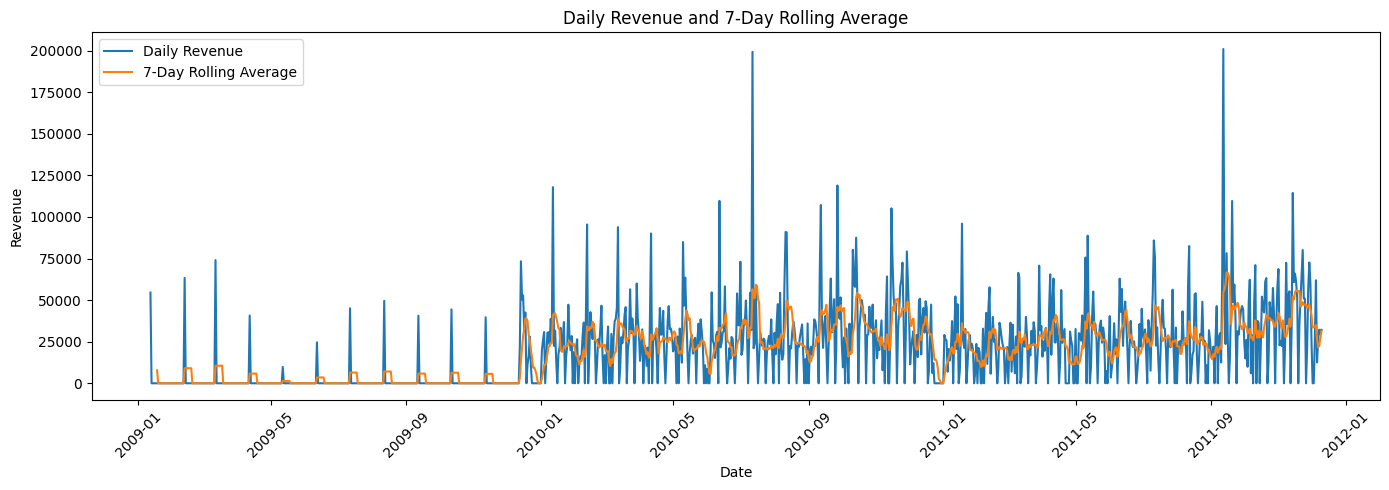

In [ ]:
#create a daily revenue trend chart
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    daily_series["InvoiceDate"],
    daily_series["Revenue"],
    label="Daily Revenue"
)

plt.plot(
    daily_series["InvoiceDate"],
    daily_series["Rolling_7_Day_Average"],
    label="7-Day Rolling Average"
)

plt.title("Daily Revenue and 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

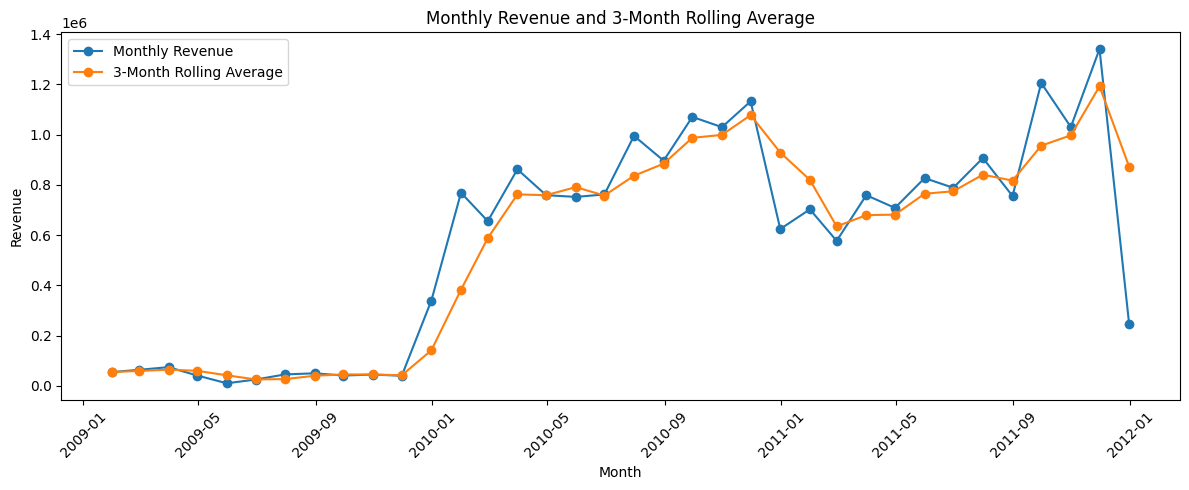

In [ ]:
# Calculate the 3-Month Rolling Average to resolve the KeyError
monthly_series["Rolling_3_Month_Average"] = (
    monthly_series["Revenue"]
    .rolling(window=3, min_periods=1)
    .mean()
)

#create a monthly revenue chart
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_series["InvoiceDate"],
    monthly_series["Revenue"],
    marker="o",
    label="Monthly Revenue"
)

plt.plot(
    monthly_series["InvoiceDate"],
    monthly_series["Rolling_3_Month_Average"],
    marker="o",
    label="3-Month Rolling Average"
)

plt.title("Monthly Revenue and 3-Month Rolling Average")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#save the final csv files
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/MVJ_Internship/Project1/day11_pandas_time_series"
)

output_dir.mkdir(parents=True, exist_ok=True)

daily_revenue.to_csv(
    output_dir / "daily_revenue_groupby.csv", index=False
)

monthly_revenue.to_csv(
    output_dir / "monthly_revenue_groupby.csv", index=False
)

daily_series.to_csv(
    output_dir / "daily_revenue_resample_rolling.csv", index=False
)

monthly_series.to_csv(
    output_dir / "monthly_revenue_resample_rolling.csv", index=False
)

print("Files saved successfully:")
for file in sorted(output_dir.glob("*.csv")):
    print(file.name)

Files saved successfully:
daily_revenue_groupby.csv
daily_revenue_resample_rolling.csv
monthly_revenue_groupby.csv
monthly_revenue_resample_rolling.csv


END OF DAY 11